# 03 · PS1 — Tài khoản fan-in / fan-out trên giao dịch ACH (HI-Small)

**Câu hỏi.** Tài khoản nhận tiền từ nhiều người gửi (fan-in) hoặc chuyển cho nhiều người nhận (fan-out) **trong một cửa sổ ngắn** có tỷ lệ liên quan rửa tiền cao hơn đối chứng không, và yếu tố thời gian có giúp gì so với chỉ đếm bậc trên cả kỳ (B3) không?

**Chạy:** chạy notebook EDA và notebook dựng graph bản mới trước, rồi *Run All* notebook này. Không phải chỉnh gì.

**Cách notebook giữ kết quả trung thực**
| Bước | Việc làm | Căn cứ |
|---|---|---|
| Kỳ | Kỳ chính (không có đuôi cuối kỳ) chia **dev** (60% đầu) / **test** (40% sau), đọc từ `analysis_period.json` | đuôi 11–18/9 gần như toàn laundering |
| Đặc trưng | fan-in/fan-out = số đối tác phân biệt lớn nhất trong cửa sổ trượt đóng $[t-W,t]$, W = 24/48h (96h: độ nhạy). Chỉ nhìn quá khứ. | Altman et al. 2023 (IBM AML); Blanuša et al. (cửa sổ trượt) |
| Đối chứng | B1 = chọn ngẫu nhiên trong tài khoản ACH; B3 = bậc phân biệt trên cả đoạn, cùng hướng, cùng số cảnh báo | Starnini et al. 2021 (degree đơn thuần bắt cả doanh nghiệp lớn) |
| Nhóm đối chiếu | loại thực thể × mức hoạt động (ngũ phân vị trên dev), gộp nhóm < 100 tài khoản | Bolton & Hand (peer group analysis) |
| Burstiness | hệ số $A_n$ hiệu chỉnh chuỗi hữu hạn | Goh & Barabási 2008; Kim & Jo 2016 |
| Chọn biến thể | 8 biến thể (2 hướng × 24/48h × thô/nhóm đối chiếu). Chọn **trên dev** theo AP, đóng băng (ghi hash), rồi mới đánh giá test | R10 |
| Đánh giá | top 0,1% / 0,5% / 1% ứng viên; precision + Wilson CI, recall, lift; cấp tài khoản và cấp giao dịch (cửa sổ đỉnh) | Saito & Rehmsmeier 2015 (AP khi lệch lớp) |
| Kết luận | **Đào sâu** nếu thắng B1 (cận dưới Wilson > tỷ lệ nền) **và** B3 ở ≥ 2/3 mức trên test, và cũng đúng trên dev; **Điều chỉnh** nếu chỉ thắng B1; **Dừng** nếu không thắng B1 hoặc < 20 tài khoản dương | R13 |

In [1]:
import hashlib
import json
import math
import os
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

if os.environ.get("HI_SMALL_ROOT"):
    ROOT = Path(os.environ["HI_SMALL_ROOT"])
else:
    ROOT = Path(r"D:\KLTN\IBM_HI_Small_EDA")
ACCOUNTS_FILE = Path(os.environ.get("HI_SMALL_ACCOUNTS", r"D:\KLTN\HI-Small_accounts.csv"))
EDGES_FILE = ROOT / "data" / "processed" / "graph" / "graph_edges.parquet"
NODES_FILE = ROOT / "data" / "processed" / "graph" / "graph_nodes.parquet"
TXN_FILE = ROOT / "data" / "processed" / "hi_small_graph_transactions.parquet"
REMOVED_FILE = ROOT / "data" / "processed" / "hi_small_removed_transactions.parquet"
PERIOD_FILE = ROOT / "reports" / "tables" / "analysis_period.json"
OUT = ROOT / "reports" / "ps1"
OUT.mkdir(parents=True, exist_ok=True)

CFG = {
    "windows_main_h": [24, 48],
    "windows_sensitivity_h": [96],
    "directions": ["in", "out"],
    "budgets": [0.001, 0.005, 0.01],
    "seed": 42,
    "stability_seeds": list(range(10)),
    "activity_bins": 5,
    "min_peer_size": 100,
    "min_burst_intervals": 5,
    "min_positives": 20,
    "min_budgets_to_win": 2,
    "candidate_rule": "account with >= 1 ACH transaction (sent or received) in the segment",
    "positive_rule": "account is sender or receiver of >= 1 laundering transaction of any format "
                     "(self-loops and duplicates included) in the segment",
}
print("03_ps1 · BẢN 15/11/2026 · kiểm tra file đầu vào...", flush=True)
NB01, NB02 = r"D:\KLTN\01_eda_hi_small.ipynb", r"D:\KLTN\02_build_graph_hi_small_duckdb.ipynb"
need = {TXN_FILE: NB01, REMOVED_FILE: NB01, PERIOD_FILE: NB01, EDGES_FILE: NB02, NODES_FILE: NB02}
missing = [f"  - {f}  → chạy {nb}" for f, nb in need.items() if not f.is_file()]
if not missing:
    _cols = {r[0] for r in duckdb.sql(f"DESCRIBE SELECT * FROM read_parquet('{EDGES_FILE.as_posix()}')").fetchall()}
    _ncols = {r[0] for r in duckdb.sql(f"DESCRIBE SELECT * FROM read_parquet('{NODES_FILE.as_posix()}')").fetchall()}
    if "from_bank_id" not in _cols or "bank_id" not in _ncols:
        missing.append(f"  - {EDGES_FILE.name} là bản cũ (chưa có bank_id)  → chạy lại {NB02}")
if missing:
    raise FileNotFoundError("Chưa đủ đầu vào cho PS1:\n" + "\n".join(missing) +
                            "\nChạy đúng bản mới trong D:\\KLTN (không phải bản trong backup_2026-11-15), theo thứ tự 01 → 02 → 03.")
print("Đủ file đầu vào.", flush=True)

period = json.loads(PERIOD_FILE.read_text(encoding="utf-8"))
SEGMENTS = ["dev", "test", "tail"]
seg_bounds_ts = [pd.Timestamp(period[k]) for k in ("main_start", "dev_end", "main_end", "data_end")]
seg_bounds = np.array([int(t.timestamp()) for t in seg_bounds_ts], dtype=np.int64)
seg_days = np.diff(seg_bounds) / 86400
display(pd.DataFrame({"segment": SEGMENTS, "start": seg_bounds_ts[:-1], "end (exclusive)": seg_bounds_ts[1:],
                      "days": seg_days.round(2)}))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
db = duckdb.connect()
_ = db.execute("SET threads = 4")

03_ps1 · BẢN 15/11/2026 · kiểm tra file đầu vào...
Đủ file đầu vào.


,segment,start,end (exclusive),days
0,dev,2022-09-01 00:00:00,2022-09-06 13:00:00,5.54
1,test,2022-09-06 13:00:00,2022-09-11 00:00:00,4.46
2,tail,2022-09-11 00:00:00,2022-09-18 16:19:00,7.68


## 1. Tập giao dịch ACH (chưa đụng tới nhãn)
Lấy mọi cạnh ACH từ đầu kỳ chính đến hết dữ liệu, gắn mỗi cạnh vào đoạn dev / test / tail theo timestamp.

In [2]:
edges = db.execute("""
    SELECT transaction_id, source_id, target_id, timestamp_s
    FROM read_parquet(?) WHERE payment_format = 'ACH' AND timestamp_s >= ?
    ORDER BY timestamp_s, transaction_id
""", [str(EDGES_FILE), int(seg_bounds[0])]).df()
nodes = db.execute("SELECT node_id, account_key, bank_id, account_id FROM read_parquet(?) ORDER BY node_id",
                   [str(NODES_FILE)]).df()
N_NODES = len(nodes)
src = edges.source_id.to_numpy(np.int64)
dst = edges.target_id.to_numpy(np.int64)
ts = edges.timestamp_s.to_numpy(np.int64)
edge_seg = np.searchsorted(seg_bounds, ts, side="right") - 1      # 0 dev, 1 test, 2 tail
print(f"ACH edges: {len(edges):,}; accounts in graph: {N_NODES:,}")
print(pd.Series(edge_seg).map(dict(enumerate(SEGMENTS))).value_counts().reindex(SEGMENTS))

ACH edges: 529,446; accounts in graph: 422,734
dev     298120
test    230611
tail       715
Name: count, dtype: int64


## 2. Fan-in / fan-out trong cửa sổ trượt
Với tài khoản $v$ và mỗi thời điểm giao dịch $t$ của nó, đếm số đối tác phân biệt có ít nhất một giao dịch trong $[t-W, t]$. Cửa sổ **không vượt qua đầu đoạn** (dev/test/tail): fan và B3 nhìn cùng một lượng dữ liệu, và nhãn cũng tính trong cùng đoạn. Các giao dịch cùng phút được thêm vào cùng lúc trước khi đếm. Điểm của $v$ trong một đoạn là **giá trị lớn nhất** trên các cửa sổ kết thúc trong đoạn đó; `end` là thời điểm kết thúc sớm nhất đạt giá trị đó (để truy lại giao dịch). Ô kiểm tra nhỏ bên dưới dùng ví dụ trong kế hoạch: A nhận 5 giao dịch từ B và 1 từ C trong 24h → fan-in = 2.

In [3]:
def sliding_peak(center, counterpart, t, window_s, bounds, n_nodes):
    """Peak number of distinct counterparts in [t - W, t], per node and per segment."""
    order = np.lexsort((t, center))
    c, p, tt = center[order], counterpart[order], t[order]
    seg = np.searchsorted(bounds, tt, side="right") - 1
    n_seg = len(bounds) - 1
    peak = np.zeros(n_nodes * n_seg, dtype=np.int64)
    end = np.full(n_nodes * n_seg, -1, dtype=np.int64)
    if len(c) == 0:
        return peak.reshape(n_nodes, n_seg), end.reshape(n_nodes, n_seg)
    starts = np.flatnonzero(np.r_[True, c[1:] != c[:-1]])
    stops = np.r_[starts[1:], len(c)]
    p_l, t_l, s_l, c_l = p.tolist(), tt.tolist(), seg.tolist(), c.tolist()
    b_l = bounds.tolist()
    pk, en = peak.tolist(), end.tolist()
    for g0, g1 in zip(starts.tolist(), stops.tolist()):
        base = c_l[g0] * n_seg
        counts = {}
        left = i = g0
        while i < g1:
            ti = t_l[i]
            j = i
            while j < g1 and t_l[j] == ti:
                q = p_l[j]
                counts[q] = counts.get(q, 0) + 1
                j += 1
            s = s_l[i]
            lo = ti - window_s
            if 0 <= s < n_seg and b_l[s] > lo:
                lo = b_l[s]          # the window never crosses the start of its segment
            while t_l[left] < lo:
                q = p_l[left]
                k = counts[q] - 1
                if k:
                    counts[q] = k
                else:
                    del counts[q]
                left += 1
            if 0 <= s < n_seg:
                d = len(counts)
                if d > pk[base + s]:
                    pk[base + s] = d
                    en[base + s] = ti
            i = j
    return np.array(pk).reshape(n_nodes, n_seg), np.array(en).reshape(n_nodes, n_seg)

# Toy check from the PS1 plan: A(0) receives 5x from B(1) and 1x from C(2) within 24h.
_c = np.array([0, 0, 0, 0, 0, 0]); _p = np.array([1, 1, 1, 1, 1, 2])
_t = np.array([0, 60, 120, 180, 240, 3600]) + 1000
_pk, _en = sliding_peak(_c, _p, _t, 24 * 3600, np.array([0, 10**9]), 3)
assert _pk[0, 0] == 2 and _en[0, 0] == 4600, (_pk, _en)
# Window is closed on the left: an edge exactly W before t still counts.
_pk, _ = sliding_peak(np.array([0, 0]), np.array([1, 2]), np.array([0, 3600]), 3600, np.array([0, 10**9]), 3)
assert _pk[0, 0] == 2
# The window does not reach back into the previous segment.
_pk, _ = sliding_peak(np.array([0, 0, 0]), np.array([1, 2, 3]), np.array([10, 20, 110]), 3600,
                      np.array([0, 100, 10**9]), 3)
assert _pk[0, 0] == 2 and _pk[0, 1] == 1, _pk
print("Toy checks passed.")

ALL_WINDOWS = CFG["windows_main_h"] + CFG["windows_sensitivity_h"]
fan = {}
t0 = time.time()
for direction in CFG["directions"]:
    center, cp = (dst, src) if direction == "in" else (src, dst)
    for W in ALL_WINDOWS:
        fan[(direction, W)] = sliding_peak(center, cp, ts, W * 3600, seg_bounds, N_NODES)
        print(f"fan_{direction}_{W}h done ({time.time() - t0:.0f}s)")

Toy checks passed.
fan_in_24h done (3s)
fan_in_48h done (6s)
fan_in_96h done (9s)
fan_out_24h done (12s)
fan_out_48h done (15s)
fan_out_96h done (18s)


## 3. B3, mức hoạt động, nhóm đối chiếu và burstiness
- **B3** = số đối tác phân biệt trong cả đoạn (cùng hướng). Ví dụ: A nhận từ 30 tài khoản cả đoạn nhưng nhiều nhất 8 trong 24h → B3_in = 30, fan_in_24h = 8.
- **Ứng viên** của một đoạn = tài khoản có ≥ 1 giao dịch ACH trong đoạn.
- **Nhóm đối chiếu** = loại thực thể (từ `HI-Small_accounts.csv`) × ngũ phân vị số giao dịch ACH/ngày. Ngưỡng ngũ phân vị và việc gộp nhóm nhỏ chốt trên dev rồi áp nguyên cho test và tail.
- **Burstiness** $A_n$ (Kim & Jo 2016) trên khoảng cách giữa các giao dịch ACH liên tiếp theo từng hướng trong đoạn: $r=\sigma/\mu$, $A_n = \frac{\sqrt{n+1}\,r-\sqrt{n-1}}{(\sqrt{n+1}-2)\,r+\sqrt{n-1}}$. Để NA nếu ít hơn 5 khoảng cách hoặc $\mu=0$.

In [4]:
n_seg = len(SEGMENTS)
def per_segment_distinct(center, cp):
    out = np.zeros((N_NODES, n_seg), dtype=np.int64)
    ok = (edge_seg >= 0) & (edge_seg < n_seg)
    key = pd.DataFrame({"c": center[ok], "p": cp[ok], "s": edge_seg[ok]}).drop_duplicates()
    cnt = key.groupby(["c", "s"]).size()
    out[cnt.index.get_level_values(0), cnt.index.get_level_values(1)] = cnt.to_numpy()
    return out

b3 = {"in": per_segment_distinct(dst, src), "out": per_segment_distinct(src, dst)}
activity = np.zeros((N_NODES, n_seg), dtype=np.int64)
ok = (edge_seg >= 0) & (edge_seg < n_seg)
np.add.at(activity, (src[ok], edge_seg[ok]), 1)
np.add.at(activity, (dst[ok], edge_seg[ok]), 1)
activity_per_day = activity / seg_days

# Entity type from accounts.csv (Bank ID compared as an integer).
acc = db.execute("""
    SELECT TRY_CAST("Bank ID" AS BIGINT) AS bank_id, CAST("Account Number" AS VARCHAR) AS account_id,
           coalesce(nullif(regexp_extract(CAST("Entity Name" AS VARCHAR), '^(.*?) #', 1), ''), 'Unknown') AS entity_type
    FROM read_csv(?, header = true, all_varchar = true)
""", [str(ACCOUNTS_FILE)]).df() if ACCOUNTS_FILE.is_file() else pd.DataFrame(columns=["bank_id", "account_id", "entity_type"])
etype = nodes.merge(acc.drop_duplicates(["bank_id", "account_id"]), on=["bank_id", "account_id"], how="left")
etype = etype.sort_values("node_id").entity_type.fillna("Unknown").to_numpy()
print("Entity types:", pd.Series(etype).value_counts().to_dict())
if not ACCOUNTS_FILE.is_file():
    print(f"Note: {ACCOUNTS_FILE} not found; peer groups use activity only.")

# Peer groups fixed on dev.
dev_cand = activity[:, 0] > 0
q_edges = np.unique(np.quantile(activity_per_day[dev_cand, 0], np.linspace(0, 1, CFG["activity_bins"] + 1)[1:-1]))
def raw_group(seg):
    b = np.searchsorted(q_edges, activity_per_day[:, seg], side="right")
    return np.char.add(np.char.add(etype.astype(str), "|q"), b.astype(str))
dev_groups = pd.Series(raw_group(0)[dev_cand]).value_counts()
etype_sizes = pd.Series(etype[dev_cand]).value_counts()
def peer_group(seg):
    g = pd.Series(raw_group(seg))
    small = ~g.isin(dev_groups[dev_groups >= CFG["min_peer_size"]].index)
    e = pd.Series(etype)
    g[small] = e[small] + "|all"
    tiny = small & ~e.isin(etype_sizes[etype_sizes >= CFG["min_peer_size"]].index)
    g[tiny] = "ALL"
    return g.to_numpy()
peer = np.stack([peer_group(s) for s in range(n_seg)], axis=1)
print("Activity quintile edges (ACH tx/day, dev):", np.round(q_edges, 3))
display(pd.Series(peer[dev_cand, 0]).value_counts().rename("dev accounts per peer group").to_frame())

def burstiness(center):
    df = pd.DataFrame({"c": center[ok], "t": ts[ok], "s": edge_seg[ok]}).sort_values(["c", "s", "t"])
    same = (df.c.to_numpy()[1:] == df.c.to_numpy()[:-1]) & (df.s.to_numpy()[1:] == df.s.to_numpy()[:-1])
    gaps = pd.DataFrame({"c": df.c.to_numpy()[1:][same], "s": df.s.to_numpy()[1:][same],
                         "g": np.diff(df.t.to_numpy())[same].astype(float)})
    agg = gaps.groupby(["c", "s"]).g.agg(["count", "mean", "std"])
    agg["std"] = gaps.groupby(["c", "s"]).g.std(ddof=0)
    n, mu, sd = agg["count"].to_numpy(float), agg["mean"].to_numpy(), agg["std"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        r = sd / mu
        a = (np.sqrt(n + 1) * r - np.sqrt(n - 1)) / ((np.sqrt(n + 1) - 2) * r + np.sqrt(n - 1))
    a[(n < CFG["min_burst_intervals"]) | ~(mu > 0)] = np.nan
    out = np.full((N_NODES, n_seg), np.nan)
    out[agg.index.get_level_values(0), agg.index.get_level_values(1)] = a
    return out

burst = {"in": burstiness(dst), "out": burstiness(src)}
print("Burstiness computed.")

Entity types: {'Partnership': 153705, 'Corporation': 139061, 'Sole Proprietorship': 123697, 'Country': 5612, 'Individual': 601, 'Direct': 58}
Activity quintile edges (ACH tx/day, dev): [0.18  0.361 0.902]


,dev accounts per peer group
Partnership|q1,42009
Corporation|q1,40425
Sole Proprietorship|q1,33181
Partnership|q2,17724
Corporation|q2,16892
Sole Proprietorship|q2,15460
Partnership|q3,15379
Sole Proprietorship|q3,15170
Corporation|q3,13342
Individual|q1,206


Burstiness computed.


## 4. Các biến thể điểm và cách xếp hạng
- Biến thể **chính** (đủ điều kiện chọn): `fan_{in|out}_{24|48}h` × {`raw`, `peer`} = 8 biến thể. `peer` = phân vị trong nhóm đối chiếu (đồng hạng phân vị thì xếp theo fan thô).
- **B3** cùng hướng và cùng kiểu chuẩn hóa với biến thể chính.
- **Độ nhạy** (không được chọn): cửa sổ 96h; burstiness đứng một mình; biến thể chính dùng burstiness để phá đồng hạng.
- Đồng hạng còn lại được phá bằng thứ tự ngẫu nhiên có seed, chốt trước khi ghép nhãn. Bảng kết quả ghi số tài khoản được chọn nhờ phá đồng hạng.

In [5]:
def peer_pct(values, seg):
    s = pd.Series(values.astype(float))
    return s.groupby(peer[:, seg]).rank(pct=True, method="average").to_numpy()

def variant_keys(name, seg):
    """Sort keys for a variant in a segment, most important first (higher = more suspicious)."""
    parts = name.split("_")
    if parts[0] == "burst":
        b = burst[parts[1]][:, seg]
        return [np.where(np.isnan(b), -np.inf, b)]
    norm = parts[-1]
    if parts[0] == "fan":
        direction, W = parts[1], int(parts[2][:-1])
        raw = fan[(direction, W)][0][:, seg].astype(float)
    else:  # b3
        direction = parts[1]
        raw = b3[direction][:, seg].astype(float)
    keys = [raw] if norm == "raw" else [peer_pct(raw, seg), raw]
    if name.endswith("+burst"):
        b = burst[direction][:, seg]
        keys.append(np.where(np.isnan(b), -np.inf, b))
    return keys

def ranking(keys, cand, seed):
    idx = np.flatnonzero(cand)
    jitter = np.random.default_rng(seed).random(len(idx))
    order = np.lexsort([jitter] + [-k[idx] for k in reversed(keys)])
    return idx[order]

MAIN_VARIANTS = [f"fan_{d}_{W}h_{n}" for d in CFG["directions"] for W in CFG["windows_main_h"] for n in ("raw", "peer")]
def b3_for(v):
    d, n = v.split("_")[1], v.split("_")[-1]
    return f"b3_{d}_{n}"
print(MAIN_VARIANTS)

['fan_in_24h_raw', 'fan_in_24h_peer', 'fan_in_48h_raw', 'fan_in_48h_peer', 'fan_out_24h_raw', 'fan_out_24h_peer', 'fan_out_48h_raw', 'fan_out_48h_peer']


## 5. Ghép nhãn (chỉ sau khi đã có toàn bộ điểm)
Tài khoản dương trong một đoạn = gửi hoặc nhận ≥ 1 giao dịch laundering **bất kỳ phương thức** trong đoạn, kể cả self-loop và dòng trùng đã bị loại khỏi graph. Recall báo theo hai mẫu số: trong tập ứng viên ACH, và trên mọi tài khoản dương của đoạn.

In [6]:
seg_case = (f"CASE WHEN ts < {seg_bounds[0]} THEN -1 WHEN ts < {seg_bounds[1]} THEN 0 "
            f"WHEN ts < {seg_bounds[2]} THEN 1 WHEN ts < {seg_bounds[3]} THEN 2 ELSE 3 END")
db.execute(f"""
    CREATE OR REPLACE TEMP VIEW all_tx AS
    SELECT *, {seg_case} AS seg FROM (
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT) AS ts, src, dst, payment_format, is_laundering
        FROM read_parquet(?)
        UNION ALL
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT) AS ts, src, dst, payment_format, is_laundering
        FROM read_parquet(?)
    )
""".replace("?", "'" + str(TXN_FILE).replace("'", "''") + "'", 1).replace("?", "'" + str(REMOVED_FILE).replace("'", "''") + "'", 1))
# Numeric columns only (5M rows): transaction id, segment, ACH flag, label.
labels = db.execute("""SELECT transaction_id, seg, (payment_format = 'ACH') AS is_ach, is_laundering
                       FROM all_tx""").df()
tx_label = pd.Series(labels.is_laundering.to_numpy(), index=labels.transaction_id.to_numpy())

pos_keys = db.execute("""
    SELECT DISTINCT seg, k FROM (
        SELECT seg, src AS k FROM all_tx WHERE is_laundering = 1
        UNION ALL SELECT seg, dst FROM all_tx WHERE is_laundering = 1
    ) WHERE seg BETWEEN 0 AND 2
""").df()
key_to_node = pd.Series(nodes.node_id.to_numpy(), index=nodes.account_key)
positive = np.zeros((N_NODES, n_seg), dtype=bool)
n_pos_accounts_all = np.zeros(n_seg, dtype=np.int64)
for s in range(n_seg):
    keys = pos_keys.k[pos_keys.seg == s]
    n_pos_accounts_all[s] = len(keys)
    ids = key_to_node.reindex(keys.to_numpy()).dropna().astype(np.int64).to_numpy()
    positive[ids, s] = True

cand = activity > 0
seg_summary = pd.DataFrame({
    "segment": SEGMENTS,
    "candidates": cand.sum(0),
    "positive_candidates": (cand & positive).sum(0),
    "positive_accounts_all": n_pos_accounts_all,
})
seg_summary["prevalence_pct"] = 100 * seg_summary.positive_candidates / seg_summary.candidates
seg_summary["transactions"] = [int((labels.seg == s).sum()) for s in range(n_seg)]
seg_summary["laundering_tx"] = [int(((labels.seg == s) & (labels.is_laundering == 1)).sum()) for s in range(n_seg)]
display(seg_summary)

,segment,candidates,positive_candidates,positive_accounts_all,prevalence_pct,transactions,laundering_tx
0,dev,209931,2894,3144,1.378548,3035199,2272
1,test,156284,2767,3008,1.770495,2042038,2250
2,tail,716,715,715,99.860335,1108,655


## 6. Hàm đánh giá
Precision@k kèm khoảng tin cậy Wilson 95%; recall theo hai mẫu số; lift so với tỷ lệ dương trong ứng viên (= precision kỳ vọng của B1); AP trên toàn bộ thứ tự; độ dao động precision qua 10 seed phá đồng hạng.

In [7]:
def wilson(tp, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = tp / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def average_precision(order, y):
    hits = y[order]
    if hits.sum() == 0:
        return np.nan
    prec = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return float(prec[hits].mean())

def budget_k(n_cand, b):
    return max(1, int(round(b * n_cand)))

def eval_variant(name, seg):
    c = cand[:, seg]
    y = positive[:, seg]
    keys = variant_keys(name, seg)
    order = ranking(keys, c, CFG["seed"])
    n_cand, n_pos = int(c.sum()), int((c & y).sum())
    prev = n_pos / n_cand if n_cand else np.nan
    seed_hits = [y[ranking(keys, c, s)] for s in CFG["stability_seeds"]]
    rows = []
    for b in CFG["budgets"]:
        k = budget_k(n_cand, b)
        sel = order[:k]
        tp = int(y[sel].sum())
        lo, hi = wilson(tp, k)
        kth = keys[0][order[k - 1]]
        n_eq = int((keys[0][c] == kth).sum())
        n_eq_sel = int((keys[0][sel] == kth).sum())
        seed_prec = [h[:k].mean() for h in seed_hits]
        rows.append({
            "variant": name, "segment": SEGMENTS[seg], "budget": b, "k": k,
            "tp": tp, "precision": tp / k, "wilson_lo": lo, "wilson_hi": hi,
            "recall_candidates": tp / n_pos if n_pos else np.nan,
            "recall_all_positive_accounts": tp / n_pos_accounts_all[seg] if n_pos_accounts_all[seg] else np.nan,
            "b1_precision": prev, "lift": (tp / k) / prev if prev else np.nan,
            "picked_by_tiebreak": n_eq_sel if n_eq > n_eq_sel else 0,
            "precision_seed_min": min(seed_prec), "precision_seed_max": max(seed_prec),
            "ap": average_precision(order, y), "ap_b1": prev,
            "n_candidates": n_cand, "n_positive_candidates": n_pos,
        })
    return rows, order

## 7. Chọn biến thể trên dev và đóng băng
Chỉ dùng dev. Biến thể có AP cao nhất trên dev là **biến thể chính**; biến thể tốt nhất của mỗi hướng cũng được ghi lại để trả lời câu hỏi fan-in hay fan-out. Lựa chọn được ghi vào `ps1_frozen_choice.json` kèm hash **trước** khi tính bất kỳ số nào trên test.

In [8]:
dev_rows = []
for v in MAIN_VARIANTS:
    dev_rows += eval_variant(v, 0)[0]
dev_table = pd.DataFrame(dev_rows)
dev_ap = dev_table.groupby("variant", sort=False).ap.first()
primary = dev_ap.idxmax()
best_by_direction = {d: dev_ap[[v for v in MAIN_VARIANTS if f"_{d}_" in v]].idxmax() for d in CFG["directions"]}
frozen = {"primary": primary, "primary_b3": b3_for(primary), "best_by_direction": best_by_direction,
          "dev_ap": dev_ap.round(6).to_dict(), "cfg": CFG, "period": period,
          "frozen_at": pd.Timestamp.now().isoformat(timespec="seconds")}
frozen["hash"] = hashlib.sha256(json.dumps({k: frozen[k] for k in ("primary", "best_by_direction", "cfg", "period")},
                                           sort_keys=True).encode()).hexdigest()[:16]
(OUT / "ps1_frozen_choice.json").write_text(json.dumps(frozen, indent=2, ensure_ascii=False), encoding="utf-8")
dev_table.to_csv(OUT / "ps1_variant_selection_dev.csv", index=False)
display(dev_ap.sort_values(ascending=False).rename("AP on dev").to_frame())
print(f"Primary (frozen): {primary}  | B3 counterpart: {b3_for(primary)}  | hash {frozen['hash']}")
print("Best per direction:", best_by_direction)

,AP on dev
variant,
fan_in_48h_raw,0.032983
fan_in_24h_raw,0.031808
fan_in_48h_peer,0.030527
fan_in_24h_peer,0.029517
fan_out_48h_raw,0.024386
fan_out_48h_peer,0.021265
fan_out_24h_raw,0.019550
fan_out_24h_peer,0.017123


Primary (frozen): fan_in_48h_raw  | B3 counterpart: b3_in_raw  | hash 369a3997bb05980a
Best per direction: {'in': 'fan_in_48h_raw', 'out': 'fan_out_48h_raw'}


## 8. Đánh giá cấp tài khoản trên dev, test và tail
Test là kết quả chính. Dev dùng để kiểm tra độ ổn định. Tail chỉ là kiểm tra độ nhạy (rất ít ứng viên).

In [9]:
report_variants = list(dict.fromkeys(
    [primary, b3_for(primary)]
    + [x for d in CFG["directions"] for x in (best_by_direction[d], b3_for(best_by_direction[d]))]
    + [primary + "+burst"]
    + [primary.replace(f"_{W}h_", f"_{S}h_") for W in CFG["windows_main_h"] for S in CFG["windows_sensitivity_h"]
       if f"_{W}h_" in primary]
    + [f"burst_{d}_raw" for d in CFG["directions"]]
))
rows, orders = [], {}
for seg in range(n_seg):
    for v in report_variants:
        r, o = eval_variant(v, seg)
        rows += r
        orders[(v, seg)] = o
acct = pd.DataFrame(rows)
role = {primary: "primary", b3_for(primary): "B3 (same direction/norm)", primary + "+burst": "primary + burstiness tie-break"}
for d in CFG["directions"]:
    role.setdefault(best_by_direction[d], f"best fan-{d}")
    role.setdefault(b3_for(best_by_direction[d]), f"B3 fan-{d}")
acct["role"] = acct.variant.map(role).fillna("sensitivity")
acct.to_csv(OUT / "ps1_account_metrics.csv", index=False)

show = acct[acct.segment == "test"][["role", "variant", "budget", "k", "tp", "precision", "wilson_lo", "wilson_hi",
                                     "b1_precision", "lift", "recall_candidates", "picked_by_tiebreak",
                                     "precision_seed_min", "precision_seed_max", "ap"]]
display(show.round(4))

,role,variant,budget,k,tp,precision,wilson_lo,wilson_hi,b1_precision,lift,recall_candidates,picked_by_tiebreak,precision_seed_min,precision_seed_max,ap
24,primary,fan_in_48h_raw,0.001,156,10,0.0641,0.0352,0.1140,0.0177,3.6206,0.0036,0,0.0641,0.0641,0.0378
25,primary,fan_in_48h_raw,0.005,781,67,0.0858,0.0681,0.1075,0.0177,4.8454,0.0242,56,0.0819,0.0858,0.0378
26,primary,fan_in_48h_raw,0.010,1563,131,0.0838,0.0711,0.0986,0.0177,4.7339,0.0473,57,0.0838,0.0877,0.0378
27,B3 (same direction/norm),b3_in_raw,0.001,156,10,0.0641,0.0352,0.1140,0.0177,3.6206,0.0036,0,0.0641,0.0641,0.0387
28,B3 (same direction/norm),b3_in_raw,0.005,781,67,0.0858,0.0681,0.1075,0.0177,4.8454,0.0242,54,0.0845,0.0883,0.0387
29,B3 (same direction/norm),b3_in_raw,0.010,1563,135,0.0864,0.0734,0.1013,0.0177,4.8784,0.0488,49,0.0857,0.0889,0.0387
30,best fan-out,fan_out_48h_raw,0.001,156,52,0.3333,0.2641,0.4105,0.0177,18.8271,0.0188,39,0.2949,0.3269,0.0409
31,best fan-out,fan_out_48h_raw,0.005,781,85,0.1088,0.0889,0.1326,0.0177,6.1471,0.0307,328,0.1063,0.1229,0.0409
32,best fan-out,fan_out_48h_raw,0.010,1563,121,0.0774,0.0652,0.0917,0.0177,4.3725,0.0437,1110,0.0774,0.0845,0.0409
33,B3 fan-out,b3_out_raw,0.001,156,53,0.3397,0.2701,0.4171,0.0177,19.1892,0.0192,36,0.3141,0.3462,0.0442


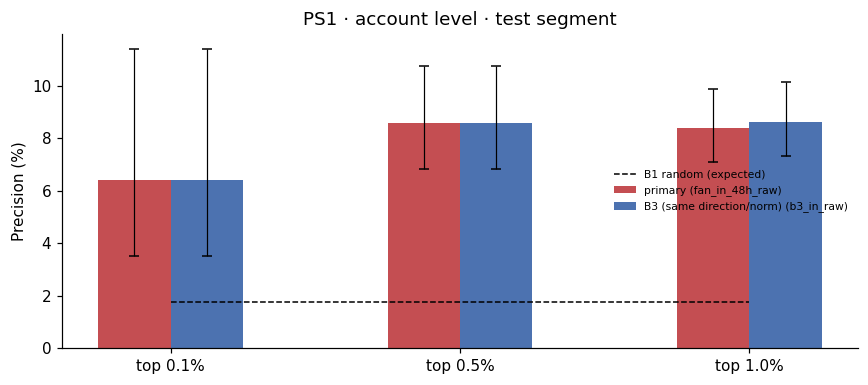

In [10]:
test = acct[acct.segment == "test"]
fig, ax = plt.subplots(figsize=(8, 3.6))
pick = [primary, b3_for(primary)]
width = 0.25
x = np.arange(len(CFG["budgets"]))
for i, (v, col) in enumerate(zip(pick, ["#C44E52", "#4C72B0"])):
    d = test[test.variant == v].sort_values("budget")
    ax.bar(x + (i - 0.5) * width, 100 * d.precision, width, color=col, label=role[v] + f" ({v})")
    ax.errorbar(x + (i - 0.5) * width, 100 * d.precision,
                yerr=[100 * (d.precision - d.wilson_lo), 100 * (d.wilson_hi - d.precision)],
                fmt="none", ecolor="black", lw=0.8, capsize=3)
b1 = 100 * test[test.variant == primary].sort_values("budget").b1_precision
ax.plot(x, b1, "k--", lw=1, label="B1 random (expected)")
ax.set_xticks(x, [f"top {b:.1%}" for b in CFG["budgets"]])
ax.set_ylabel("Precision (%)")
ax.set_title("PS1 · account level · test segment")
ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "ps1_account_precision_test.png", bbox_inches="tight"); plt.show()

## 9. Cấp giao dịch
- **PS1:** với mỗi tài khoản được chọn, gắn cờ các giao dịch ACH theo đúng hướng (vào cho fan-in, ra cho fan-out) nằm trong **cửa sổ đỉnh** $[\mathrm{end}-W, \mathrm{end}]$.
- **B3:** gắn cờ mọi giao dịch ACH theo hướng đó của tài khoản trong đoạn.
- Gộp theo `transaction_id`. Mẫu số = mọi giao dịch của đoạn trong file gốc (gồm self-loop và dòng trùng).
- Đối chứng: Random (tỷ lệ nền), ACH-only (gắn cờ mọi giao dịch ACH), và mẫu ACH ngẫu nhiên có cùng số cảnh báo với PS1.

In [11]:
eid = edges.transaction_id.to_numpy()
def project(variant, seg, k):
    order = orders[(variant, seg)]
    sel = np.zeros(N_NODES, dtype=bool); sel[order[:k]] = True
    parts = variant.split("_")
    direction = parts[1]
    center = dst if direction == "in" else src
    m = sel[center] & (edge_seg == seg)
    if parts[0] == "fan":
        W = int(parts[2][:-1]) * 3600
        end = fan[(direction, int(parts[2][:-1]))][1][:, seg][center]
        m &= (ts <= end) & (ts >= end - W)
    return np.unique(eid[m])

rng = np.random.default_rng(CFG["seed"])
tx_rows = []
for seg in range(n_seg):
    lab_s = labels[labels.seg == seg]
    n_tx, n_ill = len(lab_s), int(lab_s.is_laundering.sum())
    ach_s = lab_s[lab_s.is_ach]
    n_ach, tp_ach = len(ach_s), int(ach_s.is_laundering.sum())
    base = {"segment": SEGMENTS[seg], "n_transactions": n_tx, "n_laundering": n_ill}
    tx_rows.append({**base, "method": "Random (expected)", "budget": np.nan, "flagged": np.nan, "tp": np.nan,
                    "precision": n_ill / n_tx if n_tx else np.nan, "recall": np.nan})
    tx_rows.append({**base, "method": "ACH-only", "budget": np.nan, "flagged": n_ach, "tp": tp_ach,
                    "precision": tp_ach / n_ach if n_ach else np.nan, "recall": tp_ach / n_ill if n_ill else np.nan})
    n_cand = int(cand[:, seg].sum())
    for b in CFG["budgets"]:
        k = budget_k(n_cand, b)
        for v in (primary, b3_for(primary)):
            ids = project(v, seg, k)
            tp = int(tx_label.reindex(ids).fillna(0).sum())
            lo, hi = wilson(tp, len(ids))
            tx_rows.append({**base, "method": role[v] + f" [{v}]", "budget": b, "flagged": len(ids), "tp": tp,
                            "precision": tp / len(ids) if len(ids) else np.nan, "wilson_lo": lo, "wilson_hi": hi,
                            "recall": tp / n_ill if n_ill else np.nan})
            if v == primary and n_ach:
                m = min(len(ids), n_ach)
                draw = rng.choice(n_ach, m, replace=False)
                tp_r = int(ach_s.is_laundering.to_numpy()[draw].sum())
                tx_rows.append({**base, "method": "Random ACH sample (same size)", "budget": b, "flagged": m,
                                "tp": tp_r, "precision": tp_r / m if m else np.nan,
                                "recall": tp_r / n_ill if n_ill else np.nan})
txm = pd.DataFrame(tx_rows)
txm.to_csv(OUT / "ps1_transaction_metrics.csv", index=False)
display(txm[txm.segment == "test"].round(5))

,segment,n_transactions,n_laundering,method,budget,flagged,tp,precision,recall,wilson_lo,wilson_hi
11,test,2042038,2250,Random (expected),NaN,NaN,NaN,0.00110,NaN,NaN,NaN
12,test,2042038,2250,ACH-only,NaN,262486.0,1946.0,0.00741,0.86489,NaN,NaN
13,test,2042038,2250,primary [fan_in_48h_raw],0.001,9110.0,10.0,0.00110,0.00444,0.00060,0.00202
14,test,2042038,2250,Random ACH sample (same size),0.001,9110.0,62.0,0.00681,0.02756,NaN,NaN
15,test,2042038,2250,B3 (same direction/norm) [b3_in_raw],0.001,9188.0,10.0,0.00109,0.00444,0.00059,0.00200
16,test,2042038,2250,primary [fan_in_48h_raw],0.005,21589.0,77.0,0.00357,0.03422,0.00285,0.00446
17,test,2042038,2250,Random ACH sample (same size),0.005,21589.0,138.0,0.00639,0.06133,NaN,NaN
18,test,2042038,2250,B3 (same direction/norm) [b3_in_raw],0.005,21763.0,103.0,0.00473,0.04578,0.00390,0.00574
19,test,2042038,2250,primary [fan_in_48h_raw],0.010,28510.0,277.0,0.00972,0.12311,0.00864,0.01092
20,test,2042038,2250,Random ACH sample (same size),0.010,28510.0,191.0,0.00670,0.08489,NaN,NaN


## 10. Burstiness: độ phủ và tỷ lệ dương

In [12]:
brows = []
for seg in range(n_seg):
    for d in CFG["directions"]:
        c = cand[:, seg]
        has = c & ~np.isnan(burst[d][:, seg])
        brows.append({"segment": SEGMENTS[seg], "direction": d, "candidates": int(c.sum()),
                      "with_A_n": int(has.sum()), "coverage_pct": 100 * has.sum() / max(c.sum(), 1),
                      "positive_rate_with_A_n_pct": 100 * positive[has, seg].mean() if has.any() else np.nan,
                      "positive_rate_without_pct": 100 * positive[c & ~has, seg].mean() if (c & ~has).any() else np.nan,
                      "median_A_n_positive": np.nanmedian(burst[d][has & positive[:, seg], seg]) if (has & positive[:, seg]).any() else np.nan,
                      "median_A_n_negative": np.nanmedian(burst[d][has & ~positive[:, seg], seg]) if (has & ~positive[:, seg]).any() else np.nan})
bt = pd.DataFrame(brows)
bt.to_csv(OUT / "ps1_burstiness.csv", index=False)
display(bt.round(3))

,segment,direction,candidates,with_A_n,coverage_pct,positive_rate_with_A_n_pct,positive_rate_without_pct,median_A_n_positive,median_A_n_negative
0,dev,in,209931,13680,6.516,2.412,1.306,-0.024,-0.343
1,dev,out,209931,13276,6.324,1.687,1.358,-0.162,-0.267
2,test,in,156284,4126,2.640,5.550,1.668,0.008,-0.098
3,test,out,156284,6193,3.963,2.890,1.724,-0.145,-0.193
4,tail,in,716,19,2.654,100.000,99.857,0.118,NaN
5,tail,out,716,21,2.933,100.000,99.856,-0.003,NaN


## 11. Kết luận tự động và trả lời ba câu hỏi

In [13]:
def wins(seg_name):
    a = acct[(acct.segment == seg_name) & (acct.variant == primary)].set_index("budget")
    b = acct[(acct.segment == seg_name) & (acct.variant == b3_for(primary))].set_index("budget")
    beat_b1 = a.wilson_lo > a.b1_precision
    beat_b3 = a.precision > b.precision
    return beat_b1, beat_b3, a

need = CFG["min_budgets_to_win"]
t_b1, t_b3, a_test = wins("test")
d_b1, d_b3, _ = wins("dev")
n_pos_test = int(seg_summary.loc[1, "positive_candidates"])
if n_pos_test < CFG["min_positives"]:
    verdict = "Dừng"; reason = f"chỉ {n_pos_test} tài khoản dương trong test (< {CFG['min_positives']})"
elif (t_b1 & t_b3).sum() >= need and (d_b1 & d_b3).sum() >= need:
    verdict = "Đào sâu"; reason = f"thắng B1 và B3 ở {(t_b1 & t_b3).sum()}/3 mức trên test và {(d_b1 & d_b3).sum()}/3 trên dev"
elif t_b1.sum() >= need:
    verdict = "Điều chỉnh"
    reason = (f"thắng B1 ở {t_b1.sum()}/3 mức nhưng chỉ thắng B3 ở {(t_b1 & t_b3).sum()}/3 trên test"
              if (t_b1 & t_b3).sum() < need else "thắng trên test nhưng không ổn định trên dev")
else:
    verdict = "Dừng"; reason = f"chỉ thắng B1 ở {t_b1.sum()}/3 mức trên test"

def ap(v, seg="test"):
    return float(acct[(acct.segment == seg) & (acct.variant == v)].ap.iloc[0])
def prec(v, b, seg="test"):
    return float(acct[(acct.segment == seg) & (acct.variant == v) & (acct.budget == b)].precision.iloc[0])
bi, bo = best_by_direction["in"], best_by_direction["out"]
q1 = f"Fan-in tốt nhất ({bi}) AP test = {ap(bi):.4f}; fan-out tốt nhất ({bo}) AP test = {ap(bo):.4f} → " + \
     ("fan-in" if ap(bi) > ap(bo) else "fan-out") + " cho tín hiệu tốt hơn."
q2 = "; ".join(f"top {b:.1%}: {prec(primary, b):.2%} vs B3 {prec(b3_for(primary), b):.2%}" for b in CFG["budgets"])
q2 = f"Cửa sổ ({primary}) so với B3 ({b3_for(primary)}) trên test — {q2}. Thắng B3 ở {int(t_b3.sum())}/3 mức."
q3 = "; ".join(f"top {b:.1%}: {prec(primary + '+burst', b):.2%} vs {prec(primary, b):.2%}" for b in CFG["budgets"])
q3 = f"Thêm burstiness để phá đồng hạng — {q3}."
sens = [v for v in report_variants if "_96h_" in v]
q4 = "; ".join(f"{v}: AP test {ap(v):.4f}" for v in sens) + f" (so với {primary}: {ap(primary):.4f})" if sens else ""

decision = {
    "verdict": verdict, "reason": reason, "primary": primary, "b3": b3_for(primary), "hash": frozen["hash"],
    "test_beats_b1_by_budget": {str(k): bool(v) for k, v in t_b1.items()},
    "test_beats_b3_by_budget": {str(k): bool(v) for k, v in t_b3.items()},
    "dev_beats_b1_and_b3_by_budget": {str(k): bool(v) for k, v in (d_b1 & d_b3).items()},
    "q1_fan_in_vs_out": q1, "q2_window_vs_b3": q2, "q3_burstiness": q3, "sensitivity_96h": q4,
    "note_tail": "tail segment reported only as sensitivity; it is not used for any choice",
}
(OUT / "ps1_decision.json").write_text(json.dumps(decision, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"KẾT LUẬN PS1: {verdict} — {reason}\n")
for k in ("q1_fan_in_vs_out", "q2_window_vs_b3", "q3_burstiness", "sensitivity_96h"):
    print("•", decision[k])

KẾT LUẬN PS1: Điều chỉnh — thắng B1 ở 3/3 mức nhưng chỉ thắng B3 ở 0/3 trên test

• Fan-in tốt nhất (fan_in_48h_raw) AP test = 0.0378; fan-out tốt nhất (fan_out_48h_raw) AP test = 0.0409 → fan-out cho tín hiệu tốt hơn.
• Cửa sổ (fan_in_48h_raw) so với B3 (b3_in_raw) trên test — top 0.1%: 6.41% vs B3 6.41%; top 0.5%: 8.58% vs B3 8.58%; top 1.0%: 8.38% vs B3 8.64%. Thắng B3 ở 0/3 mức.
• Thêm burstiness để phá đồng hạng — top 0.1%: 7.69% vs 6.41%; top 0.5%: 7.81% vs 8.58%; top 1.0%: 6.85% vs 8.38%.
• fan_in_96h_raw: AP test 0.0387 (so với fan_in_48h_raw: 0.0378)


## 12. Danh sách cảnh báo trên test và file kết quả
`ps1_alerts_test.csv` liệt kê tài khoản được biến thể chính chọn ở mức 1% (kèm điểm, cửa sổ đỉnh, nhãn) để đọc từng trường hợp khi viết luận văn.

In [14]:
seg = 1
k = budget_k(int(cand[:, seg].sum()), max(CFG["budgets"]))
sel = orders[(primary, seg)][:k]
parts = primary.split("_"); d, W = parts[1], int(parts[2][:-1])
alerts = pd.DataFrame({
    "rank": np.arange(1, k + 1), "account_key": nodes.account_key.to_numpy()[sel],
    "entity_type": etype[sel], "peer_group": peer[sel, seg],
    f"fan_{d}_{W}h": fan[(d, W)][0][sel, seg],
    "window_end": pd.to_datetime(fan[(d, W)][1][sel, seg], unit="s"),
    f"b3_{d}": b3[d][sel, seg], "ach_tx_in_segment": activity[sel, seg],
    f"A_n_{d}": burst[d][sel, seg], "is_positive": positive[sel, seg],
})
alerts.to_csv(OUT / "ps1_alerts_test.csv", index=False)
display(alerts.head(20))
print("Files in", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

,rank,account_key,entity_type,peer_group,fan_in_48h,window_end,b3_in,ach_tx_in_segment,A_n_in,is_positive
0,1,4726_808FAF7C0,Partnership,Partnership|q3,88,2022-09-08 09:59:00,88,88,0.230365,False
1,2,7042_80640FE10,Partnership,Partnership|q3,82,2022-09-08 15:28:00,82,82,0.244533,False
2,3,213005_8050E2560,Partnership,Partnership|q3,82,2022-09-07 21:59:00,82,82,0.274424,False
3,4,220271_809FD0970,Partnership,Partnership|q3,80,2022-09-10 05:29:00,80,80,0.285916,False
4,5,1420_80032DB60,Partnership,Partnership|q3,80,2022-09-09 18:29:00,80,81,0.218546,False
5,6,12_800326F20,Corporation,Corporation|q3,80,2022-09-06 18:29:00,80,81,0.218546,False
6,7,227859_813A40B00,Corporation,Corporation|q3,79,2022-09-09 08:29:00,79,79,0.202752,False
7,8,1024_80299F770,Corporation,Corporation|q3,78,2022-09-10 02:59:00,78,78,0.255731,False
8,9,7042_803382430,Corporation,Corporation|q3,78,2022-09-10 21:58:00,78,78,0.167021,False
9,10,14_8007C2A40,Partnership,Partnership|q3,77,2022-09-10 11:59:00,77,77,0.202980,False


Files in D:\KLTN\IBM_HI_Small_EDA\reports\ps1
   ps1_account_metrics.csv
   ps1_account_precision_test.png
   ps1_alerts_test.csv
   ps1_burstiness.csv
   ps1_decision.json
   ps1_frozen_choice.json
   ps1_transaction_metrics.csv
   ps1_variant_selection_dev.csv
